# Market landscape

### Questions to ask:
- Which titles, companies, Job Board names, and locations show up most often?
- How do postings trend over time (weekly volume)?
- How easy is it to find remote opportunities doing data analysis? Check the trend.
- Additional breakdown by job boards (job_via): how many and which job boards cover X% of jobs...

**Idea to explore:** Job title vs. pay range plot

## Preparation
- Import necessary packages
- Load data
    - cleaning logic is managed by the Python script in a separate file.
    - Display first few records to check if it loaded
- Data collection window

In [1]:
# --- Imports ---
# python packages to use
import pandas as pd
import numpy as np
import ast  # safely parse string-encoded lists, e.g. "['sql', 'python']"
import re   # pattern-match the free-text fields (posted_at, extensions)
from collections import Counter
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS   # Useful for word frequency analysis
from wordcloud import WordCloud   # Use to create word clouds
import matplotlib.pyplot as plt   # a few quick structural/distribution charts below
from IPython.display import Markdown, display

pd.set_option("display.max_columns", 50)
pd.set_option("display.max_colwidth", 100)

In [2]:
# Call functions to run source file check and clearn up, prepare the dataframe
import sys
sys.path.append("../src")
from data_prep import load_and_clean, top_n_values

df = load_and_clean("../raw/gsearch_jobs.csv")
df.head()

,title,company_name,location,via,description,extensions,job_id,thumbnail,posted_at,schedule_type,work_from_home,salary,search_term,date_time,search_location,commute_time,salary_pay,salary_rate,salary_avg,salary_min,salary_max,salary_hourly,salary_yearly,salary_standardized,description_tokens,skills_list,ext_time,ext_salary_text,ext_flags,flag_health_insurance,flag_no_degree_mentioned,via_clean,hours_since_posted,posted_date,state,location_type,title_role,title_seniority,title_level_numeral
0,Data Analyst,Meta,Anywhere,via LinkedIn,"In the intersection of compliance and analytics, we are seeking an analytical and data-savvy sel...","['15 hours ago', '101K–143K a year', 'Work from home', 'Full-time']",eyJqb2JfdGl0bGUiOiJEYXRhIEFuYWx5c3QiLCJodGlkb2NpZCI6IlhBR01sSV93cUdRQUFBQUFBQUFBQUE9PSIsInV1bGUi...,https://encrypted-tbn0.gstatic.com/images?q=tbn:ANd9GcSGWd4ZbDsuXA2YQ7fwMam4nW4cokBZJJYHlWXaRfs&s,15 hours ago,Full-time,True,101K–143K a year,data analyst,2023-08-04 03:00:13.797776,United States,NaN,101K–143K,a year,122000.0,101000.0,143000.0,NaN,122000.0,122000.0,"['tableau', 'r', 'python', 'sql']","[tableau, r, python, sql]",[15 hours ago],[101K–143K a year],"[Work from home, Full-time]",False,False,LinkedIn,15.0,2023-08-03 12:00:13.797776,NaN,Remote,Data Analyst,Not specified,NaN
1,Data Analyst,ATC,United States,via LinkedIn,Job Title: Entry Level Business Analyst / Product Owner U.S. Citizens and those authorized to wo...,"['12 hours ago', 'Full-time', 'Health insurance']",eyJqb2JfdGl0bGUiOiJEYXRhIEFuYWx5c3QiLCJodGlkb2NpZCI6InJ4WUhwWTd4aTNRQUFBQUFBQUFBQUE9PSIsInV1bGUi...,https://encrypted-tbn0.gstatic.com/images?q=tbn:ANd9GcS9pL2p8JqLIXvaGeM9_bc7EXVkXWuBzWI204SfKIU&s,12 hours ago,Full-time,NaN,NaN,data analyst,2023-08-04 03:00:13.797776,United States,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,[],[],[12 hours ago],[],"[Full-time, Health insurance]",True,False,LinkedIn,12.0,2023-08-03 15:00:13.797776,NaN,Nationwide/Unspecified,Data Analyst,Not specified,NaN
2,Aeronautical Data Analyst,"Garmin International, Inc.","Olathe, KS",via Indeed,"Overview:\n\nWe are seeking a full-time...\nAeronautical Data Analyst in our Olathe, KS location...","['18 hours ago', 'Full-time']",eyJqb2JfdGl0bGUiOiJBZXJvbmF1dGljYWwgRGF0YSBBbmFseXN0IiwiaHRpZG9jaWQiOiJtU2xQSUxycndaY0FBQUFBQUFB...,NaN,18 hours ago,Full-time,NaN,NaN,data analyst,2023-08-04 03:00:13.797776,United States,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,['sql'],[sql],[18 hours ago],[],[Full-time],False,False,Indeed,18.0,2023-08-03 09:00:13.797776,KS,Specific location,Data Analyst,Not specified,NaN
3,Data Analyst - Consumer Goods - Contract to Hire,Upwork,Anywhere,via Upwork,Enthusiastic Data Analyst for processing sales data in Excel and communicate with clients. Hours...,"['12 hours ago', '15–25 an hour', 'Work from home', 'Contractor', 'No degree mentioned']",eyJqb2JfdGl0bGUiOiJEYXRhIEFuYWx5c3QgLSBDb25zdW1lciBHb29kcyAtIENvbnRyYWN0IHRvIEhpcmUiLCJodGlkb2Np...,NaN,12 hours ago,Contractor,True,15–25 an hour,data analyst,2023-08-04 03:00:13.797776,United States,NaN,15–25,an hour,20.0,15.0,25.0,20.0,NaN,41600.0,"['powerpoint', 'excel', 'power_bi']","[powerpoint, excel, power_bi]",[12 hours ago],[15–25 an hour],"[Work from home, Contractor, No degree mentioned]",False,True,Upwork,12.0,2023-08-03 15:00:13.797776,NaN,Remote,Data Analyst,Not specified,NaN
4,Data Analyst | Workforce Management,Krispy Kreme,United States,via LinkedIn,Overview of Position\n\nThis position will be the primary person responsible for all Workforce M...,"['7 hours ago', '90K–110K a year', 'Contractor']",eyJqb2JfdGl0bGUiOiJEYXRhIEFuYWx5c3QgfCBXb3JrZm9yY2UgTWFuYWdlbWVudCIsImh0aWRvY2lkIjoibUhMMHlaX1Rr...,https://encrypted-tbn0.gstatic.com/images?q=tbn:ANd9GcRRV1lShEQRsstSpp3yi846fCWv72q10JAm0_pNpHc&s,7 hours ago,Contractor,NaN,90K–110K a year,data analyst,2023-08-04 03:00:13.797776,United States,NaN,90K–110K,a year,100000.0,90000.0,110000.0,NaN,100000.0,100000.0,"['powerpoint', 'excel', 'outlook', 'word']","[powerpoint, excel, outlook,

In [3]:
start_date = df["posted_date"].min().strftime("%B %d, %Y")
end_date = df["posted_date"].max().strftime("%B %d, %Y")

display(Markdown(f"**Data collection window:** {start_date} to {end_date}"))

**Data collection window:** November 03, 2022 to April 18, 2025

### Taking closer look at the job titles and the posting companies

- What are some variations?
- What are the most common job titles?
- What may be the breakdown by Company names & Job Boards?

In [4]:
### Job title variations
total_posting = df.shape[0]
title_variation = df["title"].nunique()
display(Markdown(f"Total number of post: {total_posting}"))
display(Markdown(f"Data analyst title variations: {title_variation}"))

Total number of post: 61953

Data analyst title variations: 23292

Data analyst roles are advertised under a wide variety of job titles.

In [5]:
most_likely_titles = top_n_values(df, "title", 10)
display(most_likely_titles)

,count,pct_of_rows
title,,
Data Analyst,6444,10.4
Senior Data Analyst,1748,2.8
Data Scientist,931,1.5
Data Analyst II,644,1.0
Business Data Analyst,495,0.8
Lead Data Analyst,428,0.7
Survey Data Analyst,422,0.7
Data Engineer,375,0.6
Business Intelligence Analyst,343,0.6


To better understand the key elements surrounding the job titles, I will try creating a word cloud using the top 30 most frequent words that appear in the job titles.

Stop words are removed using the package.

Some Roman numerals appear in the job titles, which may indicate some seniority levels. In addition, 'business intelligence' is treated as one phrase and 'bi' is mapped to 'business intelligence'

From the resulting word cloud, we can infer seniority levels (senior, II, III, intern etc.) and career path variations (analyst, scientist, engineer, developer, business intelligence).



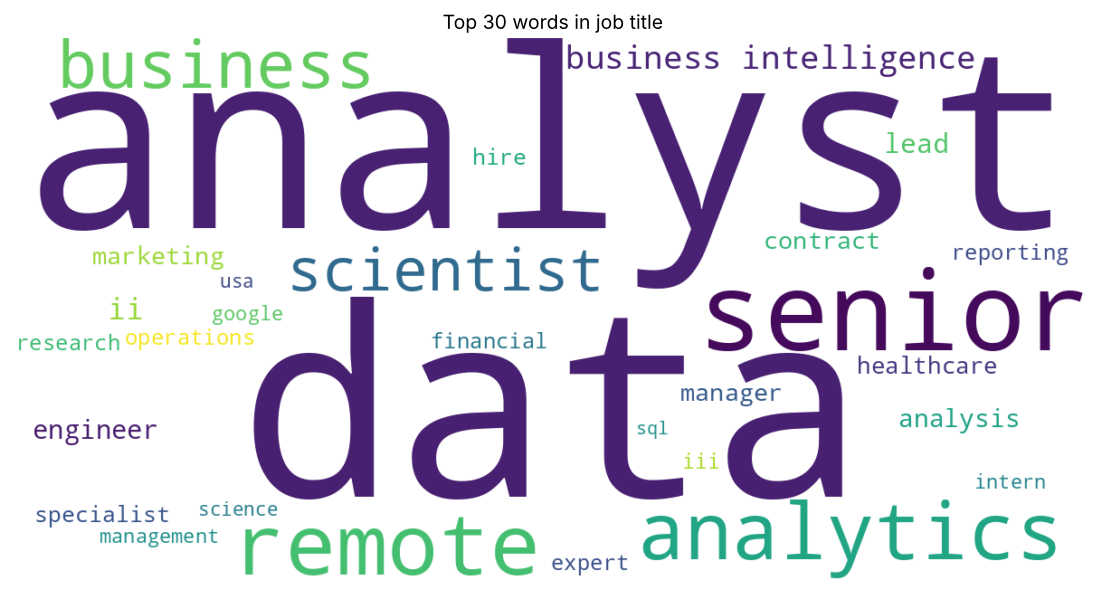

In [6]:
# Multi-word phrases to treat as one concept before tokenizing (joined with a
# hyphen so the existing word-tokenizer regex, which already allows hyphens
# mid-word, doesn't split them back apart).
STOPWORDS = set(ENGLISH_STOP_WORDS)

PHRASE_JOINS = {
    "business intelligence": "business-intelligence",
}

WORD_MAP = {
    "bi": "business intelligence",                    # abbreviation
    "business-intelligence": "business intelligence", # spelled-out, now joined
    "sr": "senior",
}

def word_frequency(series, stopwords=STOPWORDS, phrase_joins=None, word_map=None,
                    skip_words=None, min_word_len=2):
    """Count word frequency across a text column. phrase_joins merges known
    multi-word phrases into one token first; word_map then merges abbreviations
    (or the joined phrase) into a canonical display label; skip_words drops
    tokens entirely (e.g. numbering)."""
    phrase_joins = phrase_joins or {}
    word_map = word_map or {}
    skip_words = skip_words or set()
    counts = Counter()
    for text in series.dropna():
        t = text.lower()
        for phrase, joined in phrase_joins.items():
            t = t.replace(phrase, joined)
        for word in re.findall(r"[A-Za-z][A-Za-z'-]+", t):
            if len(word) < min_word_len or word in stopwords or word in skip_words:
                continue
            word = word_map.get(word, word)
            counts[word] += 1
    return counts

title_word_counts = word_frequency(df['title'], phrase_joins=PHRASE_JOINS,
                                    word_map=WORD_MAP, skip_words=None)

# --- Word cloud: top 30 words in job title ---------------------------------
top_30_words = dict(title_word_counts.most_common(30))

wc = WordCloud(
    width=1200,
    height=600,
    background_color="white",
    colormap="viridis",
    prefer_horizontal=1.0,   # keep words readable, minimal rotation
    random_state=42,         # reproducible layout across reruns
).generate_from_frequencies(top_30_words)

fig, ax = plt.subplots(figsize=(12, 6))
ax.imshow(wc, interpolation="bilinear")
ax.axis("off")
ax.set_title("Top 30 words in job title", fontsize=14)
plt.tight_layout()
plt.show()

In [7]:
# Check company names. Which company names appear the most?
top_hiring_companies = top_n_values(df, "company_name", 25)
display(Markdown("**Top 25 Companies with Most Hiring Ads**"))
display(top_hiring_companies)

**Top 25 Companies with Most Hiring Ads**

,count,pct_of_rows
company_name,,
Upwork,7533,12.2
Talentify.io,2118,3.4
Walmart,1829,3.0
vmysmartpros,1415,2.3
Dice,862,1.4
EDWARD JONES,747,1.2
Corporate,612,1.0
Cox Communications,538,0.9
Insight Global,483,0.8


Many of these names look like Job Board and staffing agency.

It may be better to see who are posting these ADs so that we know where/which site to look.

In [8]:
top_job_posters = top_n_values(df, "via_clean", 25)
display(Markdown(f"===== Who are posting these jobs (Top 25) ======="))
display(top_job_posters)

===== Who are posting these jobs (Top 25) =======

,count,pct_of_rows
via_clean,,
LinkedIn,22399,36.2
BeBee,8315,13.4
Upwork,7505,12.1
ZipRecruiter,3171,5.1
Trabajo.org,3117,5.0
Indeed,2051,3.3
Mysmartpros,1417,2.3
Snagajob,1099,1.8
Adzuna,868,1.4


LinkedIn, BeBee, and Upwork account for the large majority of postings. The first two are conventional job boards, but Upwork is a freelance marketplace, not a traditional employer job board. Its listings are gig/contract work, not full-time job openings. That's worth flagging before reading too much into any "percent of all postings" stat elsewhere in this notebook, since those numbers blend two structurally different markets together. A closer look at just the Upwork slice follows below.

### A closer look at Upwork postings

In [9]:
upwork = df[df["via_clean"] == "Upwork"]
print(f"Upwork postings: {len(upwork):,} ({len(upwork)/len(df)*100:.1f}% of all postings)")

schedule_pct = (upwork["schedule_type"].value_counts(normalize=True) * 100).round(1)
display(schedule_pct.head(5))

Upwork postings: 7,505 (12.1% of all postings)


schedule_type
Contractor                              60.1
Contractor and Temp work                36.4
Full-time                                1.1
Full-time, Contractor, and Temp work     1.0
Part-time                                0.7
Name: proportion, dtype: float64

96.5% of Upwork postings are tagged "Contractor" or "Contractor and Temp work". This is gig/freelance work, not traditional employment.

In [10]:
role_seniority_comparison = pd.DataFrame({
    "Upwork %": (upwork["title_role"].value_counts(normalize=True) * 100).round(1),
    "All postings %": (df["title_role"].value_counts(normalize=True) * 100).round(1),
})
display(role_seniority_comparison)

seniority_comparison = pd.DataFrame({
    "Upwork %": (upwork["title_seniority"].value_counts(normalize=True) * 100).round(1),
    "All postings %": (df["title_seniority"].value_counts(normalize=True) * 100).round(1),
})
display(seniority_comparison.sort_values("All postings %", ascending=False))

,Upwork %,All postings %
title_role,,
Data Analyst,72.2,84.6
Data Specialist/Other,24.0,7.2
Data Scientist,2.7,5.0
Data Engineer,1.1,3.3


,Upwork %,All postings %
title_seniority,,
Not specified,96.1,73.3
Senior,1.2,15.5
Lead,0.4,3.2
Manager,1.4,2.5
Intern,0.0,1.4
Entry-level,0.6,1.1
Junior,0.3,1.1
Principal,NaN,1.0
Director,0.0,0.5


Scientist and Engineer titles are rarer at Upwork (3.5% and 1.1% vs. 5.5% and 3.3% overall),
while skewing toward the Specialist/Other catch-all (23.2% vs. 6.6%), which tracks: ad-hoc
freelance gigs ("Excel help", "I need an expert in R") don't carry a clean role-defining word
the way a formal job posting does. Seniority is even starker: 96.1% of Upwork postings have no
seniority word at all, vs. 73.3% overall.

In [11]:
# Does salary_min/salary_max mean the same thing for Upwork as for everyone
# else? Check for unusually wide min-to-max spreads.
salary_rows = df.dropna(subset=["salary_min", "salary_max"])
salary_rows = salary_rows[salary_rows["salary_min"] > 0].copy()
salary_rows["minmax_ratio"] = salary_rows["salary_max"] / salary_rows["salary_min"]
wide_range = salary_rows[salary_rows["minmax_ratio"] > 3]

print(f"Postings with salary_max more than 3x salary_min: {len(wide_range):,}")
print(f"Of those, share that are Upwork: {(wide_range['via_clean'] == 'Upwork').mean()*100:.1f}%")
print(f"(for reference, Upwork is {(salary_rows['via_clean'] == 'Upwork').mean()*100:.1f}% "
      f"of all postings that have salary data at all)")

Postings with salary_max more than 3x salary_min: 468
Of those, share that are Upwork: 98.1%
(for reference, Upwork is 37.5% of all postings that have salary data at all)


98.1% of postings with an unusually wide salary_min-to-max spread are Upwork, even though Upwork is only 37.5% of postings that have salary data at all. That's the signature of a self-set freelance bid range ("$20-200/hr"), not an employer-stated pay band. This represents a real structural difference in what the salary fields mean. Worth remembering for the pay analysis in `04`: `salary_standardized` isn't directly comparable between Upwork and non-Upwork rows without accounting for this.

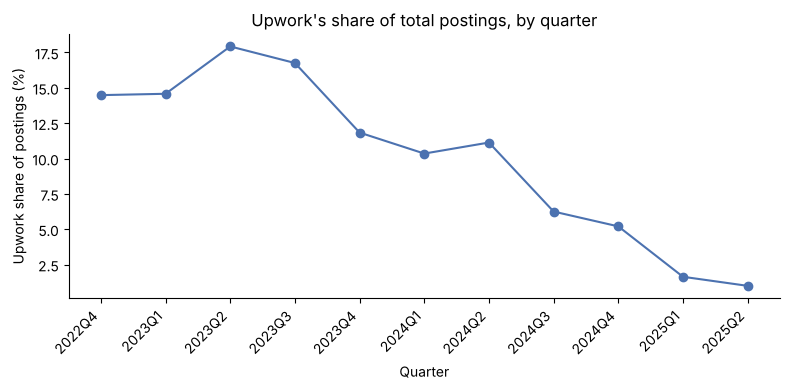

In [12]:
quarterly_upwork_share = df.groupby(df["posted_date"].dt.to_period("Q")).apply(
    lambda g: (g["via_clean"] == "Upwork").mean() * 100, include_groups=False
)

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(quarterly_upwork_share.index.astype(str), quarterly_upwork_share.values,
        marker="o", color="#4C72B0")
ax.set_xlabel("Quarter")
ax.set_ylabel("Upwork share of postings (%)")
ax.set_title("Upwork's share of total postings, by quarter")
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

Upwork's share declines steadily across the whole window from ~15-18% in 2022-2023 down to about 1% by 2025. That lines up with the data-quality caveat noted earlier in this notebook: postings right after the Aug-Sep 2024 gap already looked structurally different (more specific-city, less remote), and this is a second signal pointing the same direction -- something about what the scrape captured might have changed over time, not just how many postings there were. Worth treating any long-run trend comparison in this notebook as partly a trend in scrape composition, not purely in market demand.

### Locations & Remote Work 
- Most popular locations,
- Remote/Work from anywhere jobs count

In [13]:
# Check locations. 
locations_with_most_jobs = top_n_values(df, "location", 10)
display(Markdown(f"===== Locations with most job posts (Top 10) ======="))
display(locations_with_most_jobs)

===== Locations with most job posts (Top 10) =======

,count,pct_of_rows
location,,
Anywhere,27982,45.2
United States,15558,25.1
"Oklahoma City, OK",1437,2.3
"Kansas City, MO",1413,2.3
"Denver, CO",1062,1.7
"Jefferson City, MO",921,1.5
"Bentonville, AR",598,1.0
"Colorado Springs, CO",512,0.8
"Tulsa, OK",510,0.8


If we combine 'Anywhere' and 'United States', large portion of jobs are location-agnostic.

In [14]:
# Check 'remote' jobs
remote_or_nationwide = df["location_type"].isin(["Remote", "Nationwide/Unspecified"])

count = remote_or_nationwide.sum()
pct = remote_or_nationwide.mean() * 100

display(Markdown(f"Remote or Nationwide/Unspecified postings: {count:,} of {len(df):,} ({pct:.1f}%)"))

Remote or Nationwide/Unspecified postings: 43,540 of 61,953 (70.3%)

Many remote/work from anywhere options are available for data analysts.

### Posting Volume Over Time
- How did the number of postings changed over time (monthly volume)?
- Plot them as a line chart for easier interpretation.

,total,work_anywhere
2022-11,2160.0,1454.0
2022-12,3398.0,2369.0
2023-01,3723.0,2523.0
2023-02,2796.0,1882.0
2023-03,2741.0,1958.0
2023-04,2456.0,1746.0
2023-05,2375.0,1761.0
2023-06,2382.0,1635.0
2023-07,2562.0,1858.0
2023-08,3041.0,2085.0


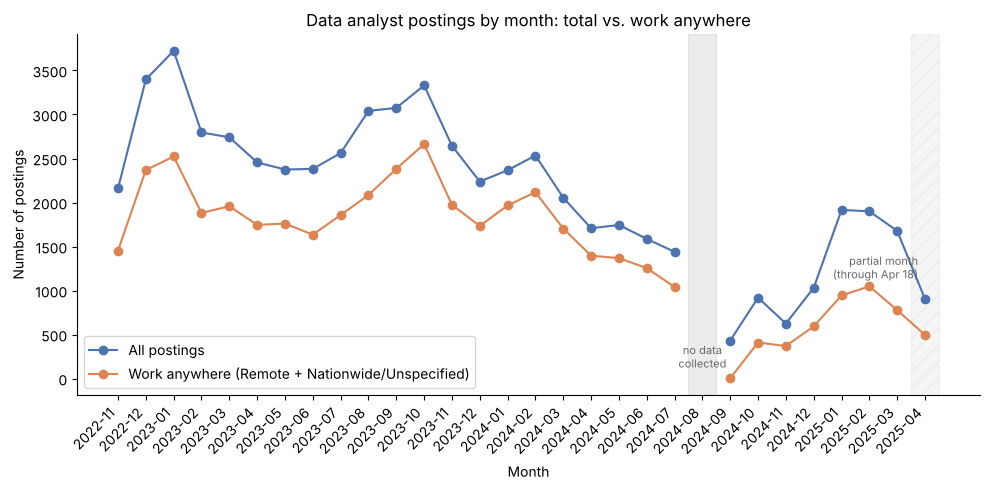

In [15]:
monthly_total = df["posted_date"].dt.to_period("M").value_counts().sort_index()

work_anywhere_df = df[df["location_type"].isin(["Remote", "Nationwide/Unspecified"])]
monthly_work_anywhere = work_anywhere_df["posted_date"].dt.to_period("M").value_counts().sort_index()

monthly_trend = pd.DataFrame({
    "total": monthly_total,
    "work_anywhere": monthly_work_anywhere,
})
# A month with real postings but zero "work anywhere" matches is a genuine
# zero, so fill that case here...
monthly_trend["work_anywhere"] = monthly_trend["work_anywhere"].fillna(0)

# ...but reindex to a complete month range AFTER that fill, so a month with
# NO rows at all (a true data-collection gap, not "zero postings") shows up
# as a real NaN instead of silently disappearing from the index.
full_range = pd.period_range(monthly_trend.index.min(), monthly_trend.index.max(), freq="M")
monthly_trend = monthly_trend.reindex(full_range)

display(monthly_trend)

x_labels = monthly_trend.index.astype(str).tolist()
gap_month = "2024-08"
gap_pos = x_labels.index(gap_month)
partial_pos = x_labels.index("2025-04")

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(x_labels, monthly_trend["total"], marker="o", color="#4C72B0", label="All postings")
ax.plot(x_labels, monthly_trend["work_anywhere"], marker="o", color="#DD8452", label="Work anywhere (Remote + Nationwide/Unspecified)")
ax.axvspan(gap_pos - 0.5, gap_pos + 0.5, color="gray", alpha=0.15, zorder=0)
ax.annotate("no data\ncollected", xy=(gap_pos, 0), xytext=(0, 8), textcoords="offset points",
            ha="center", fontsize=8, color="dimgray")
ax.axvspan(partial_pos - 0.5, partial_pos + 0.5, color="gray", alpha=0.08, hatch="//", zorder=0)
ax.annotate("partial month\n(through Apr 18)", xy=(partial_pos, monthly_trend["total"].iloc[partial_pos]),
            xytext=(-5, 15), textcoords="offset points", ha="right", fontsize=8, color="dimgray")
ax.set_xlabel("Month")
ax.set_ylabel("Number of postings")
ax.set_title("Data analyst postings by month: total vs. work anywhere")
ax.legend()
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

Postings peaked in early 2023, then declined through most of 2024. That decline isn't a clean read, though: the raw data has a gap from July 29 to September 15, 2024 — no postings at all for seven weeks — and the postings that resume afterward look different in kind, not just volume (see the note below). Postings recover through 2025, with the data ending April 18, 2025.

**Data quality note: August–September 2024 gap**

The monthly chart hides something the line makes look smooth: `posted_date`
has no records between 2024-07-29 and 2024-09-15 — a full seven-week gap,
not a slow month. `fillna(0)` in the code above doesn't add a zero row for
a month with literally no data, so the chart just draws a straight line from
July to September as if nothing happened.

The postings that resume on 2024-09-16 also don't look like the rest of the
dataset. In a typical month (e.g. August 2023), "Anywhere" and "United States"
together make up ~75% of postings. In the September 2024 batch, only 4 of 432
postings (<1%) are tagged remote. The rest are specific-city postings
concentrated in a handful of Midwest metros (Kansas City, Topeka, Bentonville,
Oklahoma City, Wichita). `search_term` and `search_location` are unchanged
across the gap, so this isn't a different query — something about what the
scrape actually captured changed for this window.

Takeaway: treat Sept–Dec 2024 as a different sample, not a continuation of
the same trend. Any conclusion about "the market cooling off" that leans on
this window specifically should be checked against 2023 and early-2024 data
instead.

In [16]:
# Add quarterly trend
quarterly_total = df["posted_date"].dt.to_period("Q").value_counts().sort_index()
work_anywhere_df = df[df["location_type"].isin(["Remote", "Nationwide/Unspecified"])]
quarterly_work_anywhere = work_anywhere_df["posted_date"].dt.to_period("Q").value_counts().sort_index()
work_anywhere_pct = quarterly_work_anywhere / quarterly_total * 100

quarterly_trend = pd.DataFrame({
    "total": quarterly_total,
    "work_anywhere": quarterly_work_anywhere,
    "work_anywhere_pct": work_anywhere_pct.round(1),
}).fillna(0)

display(quarterly_trend)

# 2025 Q2 in this data is ONLY April 1-18 -- not a real quarter, just a
# fragment of one month. Excluded from trend comparisons below (left visible
# in the table above so it's clear it was checked, not missed).
EXCLUDED_QUARTERS = ["2025Q2"]
quarterly_trend_complete = quarterly_trend.drop(
    index=[q for q in EXCLUDED_QUARTERS if q in quarterly_trend.index]
)

,total,work_anywhere,work_anywhere_pct
posted_date,,,
2022Q4,5558,3823,68.8
2023Q1,9260,6363,68.7
2023Q2,7213,5142,71.3
2023Q3,8678,6326,72.9
2023Q4,8213,6372,77.6
2024Q1,6956,5788,83.2
2024Q2,5040,4020,79.8
2024Q3,1872,1045,55.8
2024Q4,2576,1373,53.3


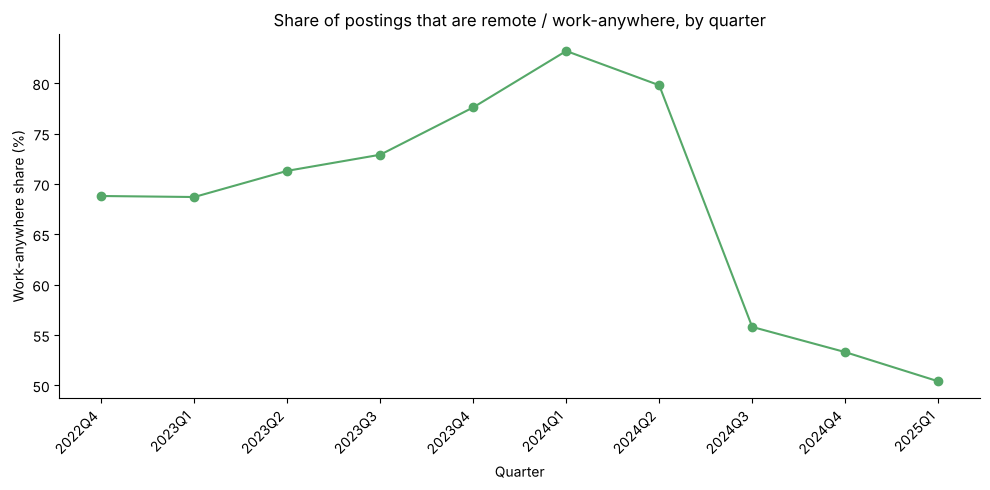

In [17]:
fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(quarterly_trend_complete.index.astype(str), quarterly_trend_complete["work_anywhere_pct"],
        marker="o", color="#55A868")
ax.set_xlabel("Quarter")
ax.set_ylabel("Work-anywhere share (%)")
ax.set_title("Share of postings that are remote / work-anywhere, by quarter")
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()


This line chart makes the trend easier to read: the work-anywhere share climbed through 2023, peaked at 83.2% in 2024 Q1, then declined fairly steadily to the 50-55% range by late 2024 and into 2025 (2025 Q2 excluded here, since it's only 18 days of April, not a full quarter).

In [18]:
low_quarter = quarterly_trend_complete["work_anywhere_pct"].idxmin()
high_quarter = quarterly_trend_complete["work_anywhere_pct"].idxmax()

display(Markdown(f"Lowest work-anywhere share: {quarterly_trend_complete.loc[low_quarter, 'work_anywhere_pct']}% in {low_quarter} (out of {quarterly_trend_complete.loc[low_quarter, 'total']:.0f} postings)"))
display(Markdown(f"Highest work-anywhere share: {quarterly_trend_complete.loc[high_quarter, 'work_anywhere_pct']}% in {high_quarter} (out of {quarterly_trend_complete.loc[high_quarter, 'total']:.0f} postings)"))

Lowest work-anywhere share: 50.4% in 2025Q1 (out of 5494 postings)

Highest work-anywhere share: 83.2% in 2024Q1 (out of 6956 postings)

Some variations have been observed in terms of the percentage of remote/anywhere jobs.

## Conclusion

Data analyst roles show up under a long tail of titles (23,000+ distinct strings across ~62,000 postings), but "Data Analyst" and its close variants (Senior, II, Business, Lead) dominate the top of that list. Postings are heavily concentrated on a handful of job boards (LinkedIn, BeBee, Upwork) and staffing/aggregator company names rather than direct employer postings.

Remote and location-agnostic ("Anywhere"/"United States") postings make up a large share of the market, though that share isn't constant: it rose from ~69% in late 2022 to a peak of 83.2% in 2024 Q1, then declined to roughly 50-55% by 2025. Two data-quality caveats apply to any trend read here: a 7-week total collection gap (Jul 29-Sep 15, 2024) where the data resumed looking structurally different, and a final month (April 2025) that's only 18 of 30 days, so 2025 Q2 is excluded from the quarterly comparisons above rather than treated as a real quarter.
